# Fashion-MNIST Dataset Exploration

Importing the required libraries

In [27]:
import os
import numpy as np
import matplotlib.pyplot as plt
from torchvision import datasets

Loading the Fashion-MNIST training dataset

In [14]:
DATA_DIR = '../data'
if not os.path.exists(DATA_DIR):
    os.makedirs(DATA_DIR)
if os.path.exists(DATA_DIR):
    try:
        print(f"Dataset found: Loading the dataset from {DATA_DIR}")
        dataset = datasets.FashionMNIST(root=DATA_DIR, train=True, download=False)
    except RuntimeError as e:
        print("Error Dataset not found, downloading the dataset")
        dataset = datasets.FashionMNIST(root=DATA_DIR, train=True, download=True)


Dataset found: Loading the dataset from ../data


In [21]:
if dataset is not None:
    CLASS_NAMES = dataset.classes
    print(f"Number of classes: {len(CLASS_NAMES)}")
    print("Class names:", CLASS_NAMES)
    dim = dataset.data.shape[1]
    print("Image dimensions:", dim, "x", dim)
    print("Number of samples:", len(dataset))

Number of classes: 10
Class names: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
Image dimensions: 28 x 28
Number of samples: 60000


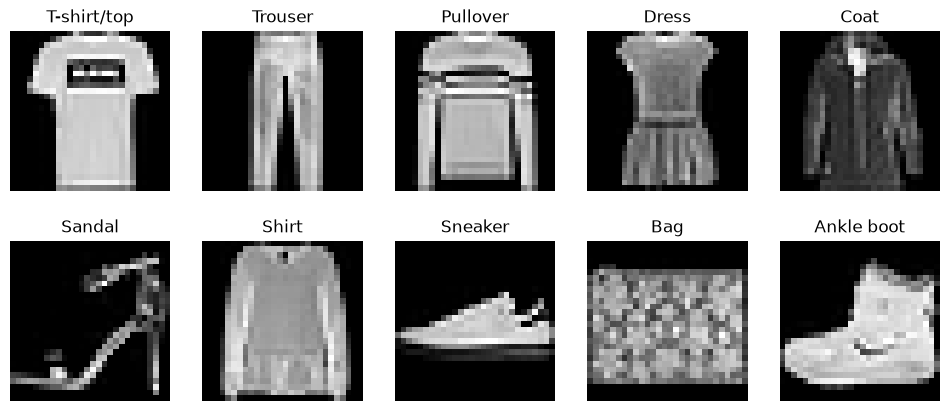

In [25]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for label, ax in enumerate(axes.flat):
    idx = int((dataset.targets == label).nonzero()[0][0].item())
    image, y = dataset[idx]
    ax.imshow(image, cmap='gray', vmin=0, vmax=255)
    ax.set_title(f"{CLASS_NAMES[y]}")
    ax.axis('off')


Inspecting Pixel Values

In [29]:
image, _ = dataset[0]

img_array = np.array(image)
min_pixel_value = np.min(img_array)
max_pixel_value = np.max(img_array)
zero_pixel_count = np.sum(img_array == 0)
total_pixel_count = img_array.size

percent_zero_pixels = (zero_pixel_count / total_pixel_count) * 100

print(f"Minimum pixel value: {min_pixel_value}")
print(f"Maximum pixel value: {max_pixel_value}")
print(f"Number of zero pixels: {zero_pixel_count}")
print(f"Total number of pixels: {total_pixel_count}")
print(f"Percentage of zero pixels: {percent_zero_pixels:.2f}%")

Minimum pixel value: 0
Maximum pixel value: 255
Number of zero pixels: 351
Total number of pixels: 784
Percentage of zero pixels: 44.77%


In [45]:
percent_of_zero_valued_pixel_list = []
for i in range(1000):
    image, _ = dataset[i]
    img_array = np.array(image)
    zero_pixel_count = np.sum(img_array == 0)
    total_pixel_count = img_array.size
    percent_zero_pixels = (zero_pixel_count / total_pixel_count) * 100
    percent_of_zero_valued_pixel_list.append(percent_zero_pixels)

Text(0, 0.5, 'Number of Images')

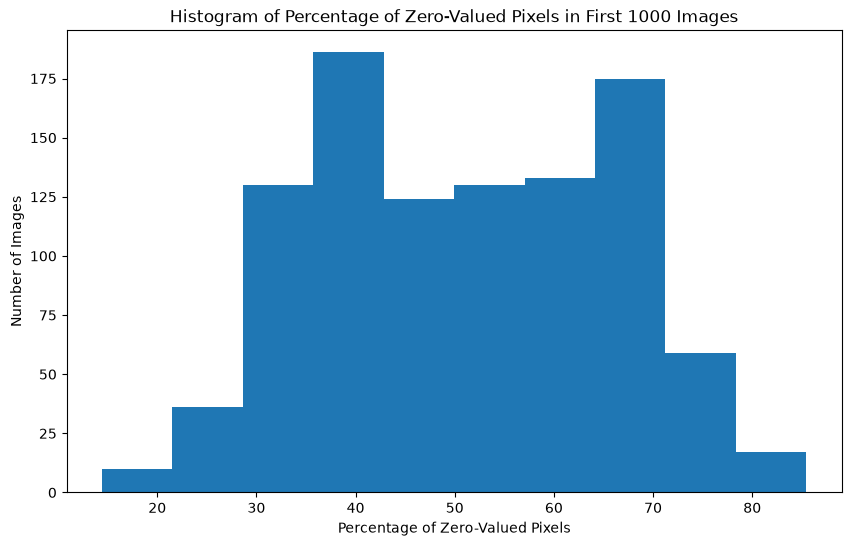

In [46]:
# Histogram of the percentage of zero-valued pixels in the first 100 images
plt.figure(figsize=(10, 6))
plt.hist(percent_of_zero_valued_pixel_list)
plt.title(f'Histogram of Percentage of Zero-Valued Pixels in First {len(percent_of_zero_valued_pixel_list)} Images')
plt.xlabel('Percentage of Zero-Valued Pixels')
plt.ylabel('Number of Images')

In [47]:
min_percent = np.min(percent_of_zero_valued_pixel_list)
max_percent = np.max(percent_of_zero_valued_pixel_list)
mean_percent = np.mean(percent_of_zero_valued_pixel_list)

print(f"Minimum percentage of zero pixels in first {len(percent_of_zero_valued_pixel_list)} images: {min_percent:.2f}%")
print(f"Maximum percentage of zero pixels in first {len(percent_of_zero_valued_pixel_list)} images: {max_percent:.2f}%")
print(f"Mean percentage of zero pixels in first {len(percent_of_zero_valued_pixel_list)} images: {mean_percent:.2f}%")

Minimum percentage of zero pixels in first 1000 images: 14.41%
Maximum percentage of zero pixels in first 1000 images: 85.46%
Mean percentage of zero pixels in first 1000 images: 50.91%
